# 02 · Disease module, hubs, bottlenecks and functional clusters

This notebook follows `src/pipeline.py` step by step on the Alzheimer's disease (AD) data:

1. Do the AD genes form a connected **disease module** in the interactome?
2. Expand the module with **DIAMOnD**, and validate it by recovering held-out disease genes.
3. **Filter** the AD network.
4. Identify **hubs and bottlenecks**, and test how fragile the network is to their removal.
5. Find **functional clusters** and annotate them by pathway enrichment.

The Cytoscape visualisation of the result is in notebook 03.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import plots
from src.clustering import cluster_network, cluster_summary, partition_stability
from src.config import load_config
from src.diamond import diamond, diamond_cross_validation
from src.disease_module import module_significance
from src.disease_network import build_disease_network
from src.enrichment import clean_term, enrich_clusters
from src.hetionet import prepare
from src.interactome import build_interactome, map_genes, symbols_to_entrez
from src.topology import centrality_table, classify_hubs_bottlenecks, key_proteins, robustness_analysis

%matplotlib inline
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 70)

config = load_config(ROOT / "config" / "config.yaml")
SEED = config["random_seed"]
data = prepare(config)
symbols = data.symbols
interactome = build_interactome(data.interactions, symbols,
                                exclude=symbols_to_entrez(config["interactome"]["exclude_symbols"], symbols))
seeds = map_genes(interactome, data.seed_genes).mapped
print(f"{interactome.number_of_nodes():,} proteins, {interactome.number_of_edges():,} interactions, {len(seeds)} seeds")

14,108 proteins, 137,912 interactions, 183 seeds


## 1. Is there an Alzheimer's disease module?

If disease genes act together, their proteins should interact more than chance. The test compares the
largest connected component (LCC) formed by the 183 seeds with the LCC of 1,000 random gene sets that have
the same degree distribution. The random sets are degree-matched because disease genes are studied more and
have more known interactions (notebook 01).

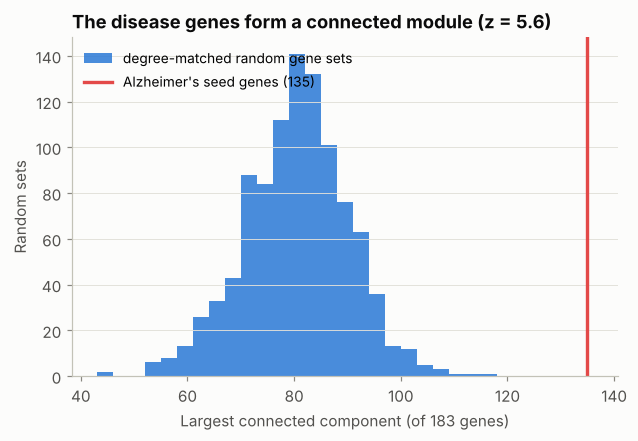

,value
genes_in_interactome,1.830e+02
observed_lcc,1.350e+02
observed_lcc_fraction,7.377e-01
random_lcc_mean,7.994e+01
random_lcc_std,9.780e+00
z_score,5.630e+00
empirical_p,9.990e-04
n_random,1.000e+03


In [2]:
significance = module_significance(interactome, seeds, n_random=1000, seed=SEED)
plots.plot_module_significance(significance.random_lcc, significance.observed_lcc, significance.z_score,
                               significance.n_genes)
plt.show()
pd.Series(significance.summary()).to_frame("value")

135 of the 183 seed proteins (74%) form one connected component. Degree-matched random sets reach about 80
(z = 5.6, empirical p < 0.001). The AD genes do form a **disease module**, which justifies analysing them as a
network.

## 2. Expanding the module with DIAMOnD

Known disease genes are an incomplete list. DIAMOnD (Ghiassian et al., 2015) adds, one at a time, the protein
whose links into the current module are least likely by chance (hypergeometric p-value).

In [3]:
ranking = diamond(interactome, seeds, n_genes=200)
ranking.insert(2, "symbol", ranking["gene"].map(symbols))
ranking.head(12)

,rank,gene,symbol,degree,links_to_module,p_value
0,1,4170,MCL1,38,9,1.007e-09
1,2,22983,MAST1,37,8,2.009e-08
2,3,140545,RNF32,41,9,2.303e-09
3,4,2639,GCDH,13,7,9.926e-11
4,5,51295,ECSIT,42,10,1.340e-10
5,6,1558,CYP2C8,11,6,2.260e-09
6,7,54536,EXOC6,19,8,5.960e-11
7,8,7001,PRDX2,33,9,3.518e-10
8,9,24138,IFIT5,17,7,1.295e-09
9,10,3437,IFIT3,27,9,5.035e-11


**Validation.** In five-fold cross-validation, one fifth of the seeds is hidden, DIAMOnD runs on the rest,
and we count how many hidden AD genes appear among its 200 additions.

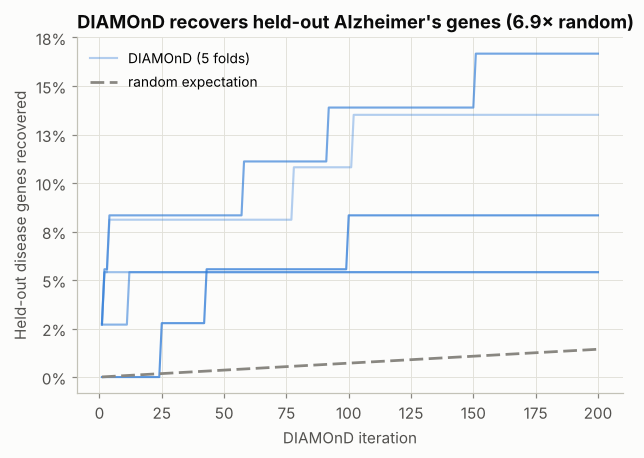

,fold,training_seeds,held_out_seeds,background,recovered,expected,fold_enrichment
0,1,146,37,13962,5,0.530,9.434
1,2,146,37,13962,2,0.530,3.774
2,3,146,37,13962,2,0.530,3.774
3,4,147,36,13961,6,0.516,11.634
4,5,147,36,13961,3,0.516,5.817


In [4]:
cv = diamond_cross_validation(interactome, seeds, n_genes=200, folds=5, seed=SEED)
plots.plot_diamond_recovery(cv, 200)
plt.show()
cv.drop(columns="recovered_ranks")

DIAMOnD recovers 18 hidden AD genes where random additions would find 2.6 (6.9× enrichment, consistent in
every fold). Most recoveries happen early in the ranking. The disease network uses the **top 50** DIAMOnD
proteins: beyond that, DIAMOnD starts absorbing a dense block of abundant proteins (ribosomal proteins,
chaperones), which would dominate the network without adding disease signal.

## 3. Building and filtering the AD network

In [5]:
network = build_disease_network(interactome, data, ranking, n_diamond=config["diamond"]["network_genes"])
graph = network.graph
network.log_frame()

,description,proteins,interactions
step,,,
seed genes,disease-associated genes (Hetionet DaG),196,NaN
in interactome,seeds present in the filtered interactome,183,NaN
module expansion,+ top 50 DIAMOnD proteins,233,NaN
induced subgraph,interactions among selected proteins,233,1086.0
largest component,drop proteins disconnected from the main network,190,1085.0


43 proteins (mostly seeds without interactions to the other selected proteins, e.g. ADAM10, CR1, ABCA1)
are dropped in the last step. The final network has **190 proteins and 1,085 interactions**: 140 known AD genes
and 50 DIAMOnD proteins.

## 4. Hubs and bottlenecks

Following Yu et al. (2007), hubs are the top 10% by degree and bottlenecks the top 10% by betweenness
(the share of shortest paths running through a protein).

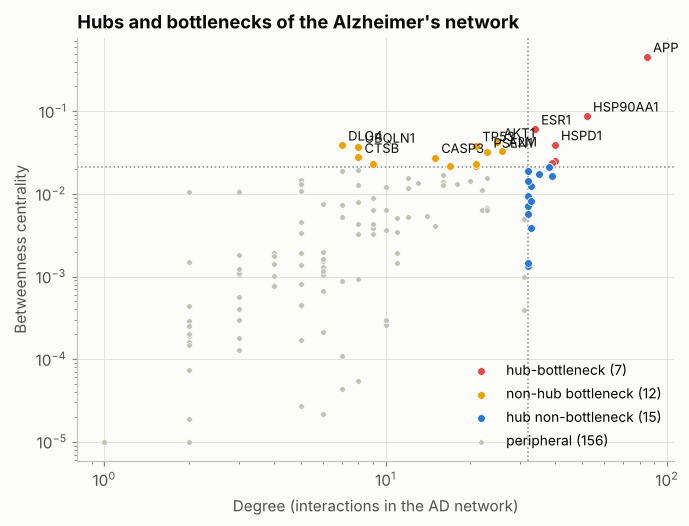

,symbol,role,centrality_class,degree,betweenness,closeness,ad_drug_target,druggable
0,APP,seed,hub-bottleneck,85,0.457,0.602,False,False
1,HSP90AA1,diamond,hub-bottleneck,52,0.087,0.525,False,True
2,ESR1,seed,hub-bottleneck,34,0.061,0.449,False,True
3,AKT1,seed,non-hub bottleneck,25,0.042,0.474,False,True
4,HSPD1,seed,hub-bottleneck,40,0.039,0.493,False,False
5,DLG4,seed,non-hub bottleneck,7,0.039,0.393,False,True
6,TP53,seed,non-hub bottleneck,21,0.038,0.412,False,True
7,UBQLN1,seed,non-hub bottleneck,8,0.037,0.402,False,False
8,A2M,seed,non-hub bottleneck,26,0.033,0.448,False,True
9,PSEN1,seed,non-hub bottleneck,23,0.032,0.464,False,False


In [6]:
centrality = classify_hubs_bottlenecks(centrality_table(graph), 0.9, 0.9)
nodes = network.node_table().merge(centrality.drop(columns="symbol"), on="id")
plots.plot_centrality_scatter(centrality)
plt.show()
key_proteins(nodes, 15)

* **APP** is by far the main bottleneck (betweenness 0.46): almost half of all shortest paths in the
  network run through the amyloid precursor protein.
* The other hub-bottlenecks are the chaperone **HSP90AA1**, **ESR1** (oestrogen receptor) and **HSPD1**.
  Several known AD genes are **non-hub bottlenecks** with few partners but a bridging position: AKT1, TP53,
  PSEN1, A2M, CASP3, CLU, DLG4 and UBQLN1. Ranking by degree alone would miss them.
* Bottleneck status is mostly a property of seed genes (11 of 12 non-hub bottlenecks are seeds), whereas
  DIAMOnD proteins are more often hubs without a bridging role (12 of 15 hub non-bottlenecks).

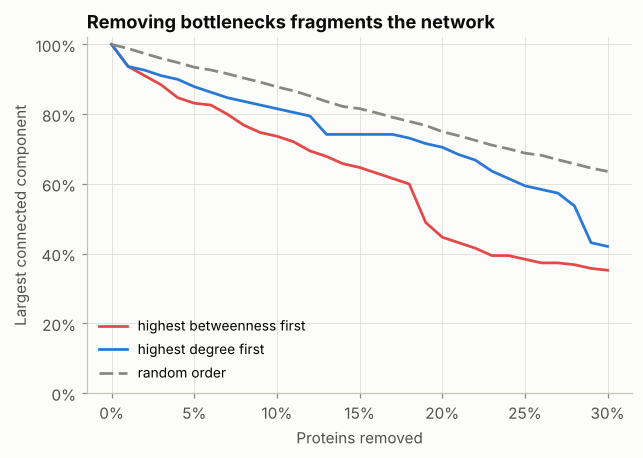

strategy,betweenness,degree,random
fraction_removed,,,
0.05,0.832,0.879,0.935
0.10,0.737,0.816,0.878
0.20,0.447,0.705,0.750


In [7]:
curves = robustness_analysis(graph, centrality, n_random=20, seed=SEED)
plots.plot_robustness(curves)
plt.show()
curves[curves["fraction_removed"].round(2).isin([0.05, 0.1, 0.2])].pivot(
    index="fraction_removed", columns="strategy", values="lcc_fraction")

Removing the 10% highest-betweenness proteins shrinks the largest component to 74% of the network,
compared with 88% for random removal. At 20% it falls to 45% (random: 75%). The bottlenecks hold the AD
network together.

**Where do current drugs act?**

In [8]:
nodes[nodes["ad_drug_target"]][["symbol", "centrality_class", "degree", "betweenness", "ad_drugs"]]

,symbol,centrality_class,degree,betweenness,ad_drugs
1,ACHE,peripheral,3,5.548e-04,Donepezil; Galantamine; Rivastigmine
33,CHRNA4,peripheral,2,1.058e-02,Galantamine
34,CHRNA7,peripheral,1,0.000e+00,Galantamine
35,CHRNB2,peripheral,1,0.000e+00,Galantamine
61,GRIN2B,peripheral,3,1.089e-03,Memantine
68,HTR2A,peripheral,2,1.506e-04,Donepezil


In [9]:
central = nodes[nodes["centrality_class"] != "peripheral"]
pd.DataFrame({
    "proteins": [len(central), len(nodes)],
    "druggable (any DrugBank compound)": [central["druggable"].mean(), nodes["druggable"].mean()],
}, index=["hubs / bottlenecks", "whole network"])

,proteins,druggable (any DrugBank compound)
hubs / bottlenecks,34,0.294
whole network,190,0.332


All six targets of the approved AD drugs (cholinesterase ACHE, nicotinic receptors CHRNA4/CHRNA7/CHRNB2,
the NMDA receptor GRIN2B and HTR2A) are **peripheral** in the network, with 1-3 interactions each. That fits
their role as symptomatic treatments of neurotransmission. The central proteins are different: 29% of the hubs
and bottlenecks (e.g. HSP90AA1, ESR1, AKT1, TP53, A2M) are bound by some DrugBank compound. They are candidates
for network-based drug repurposing, not recommendations.

## 5. Functional clusters

Louvain community detection (resolution 1.0), then pathway and GO over-representation for each cluster
(hypergeometric test against the interactome, Benjamini-Hochberg FDR).

In [10]:
labels, modularity = cluster_network(graph, "louvain", 1.0, SEED, min_size=5)
stability = partition_stability(graph, labels, runs=20, seed=SEED)
print(f"modularity {modularity:.3f}; adjusted Rand index vs 20 reruns: "
      f"mean {stability.adjusted_rand_index.mean():.2f}, min {stability.adjusted_rand_index.min():.2f}")
cluster_summary(graph, labels)

modularity 0.470; adjusted Rand index vs 20 reruns: mean 0.70, min 0.40


,cluster,size,seed_genes,diamond_genes,internal_edges,density,top_proteins
0,1,62,45,17,222,0.117,"APP, A2M, CDC37, RNF32, MAST1"
1,2,59,52,7,143,0.084,"AKT1, SNCA, TP53, BCL2, BCL2L1"
2,3,34,8,26,468,0.834,"HSP90AA1, HSPD1, VIM, YBX1, VDAC1"
3,4,26,26,0,36,0.111,"ESR1, CTSB, IGF1R, TTR, CTSD"
4,5,9,9,0,8,0.222,"DLG4, PPP5C, PRKCG, GRIN2B, GRIK2"


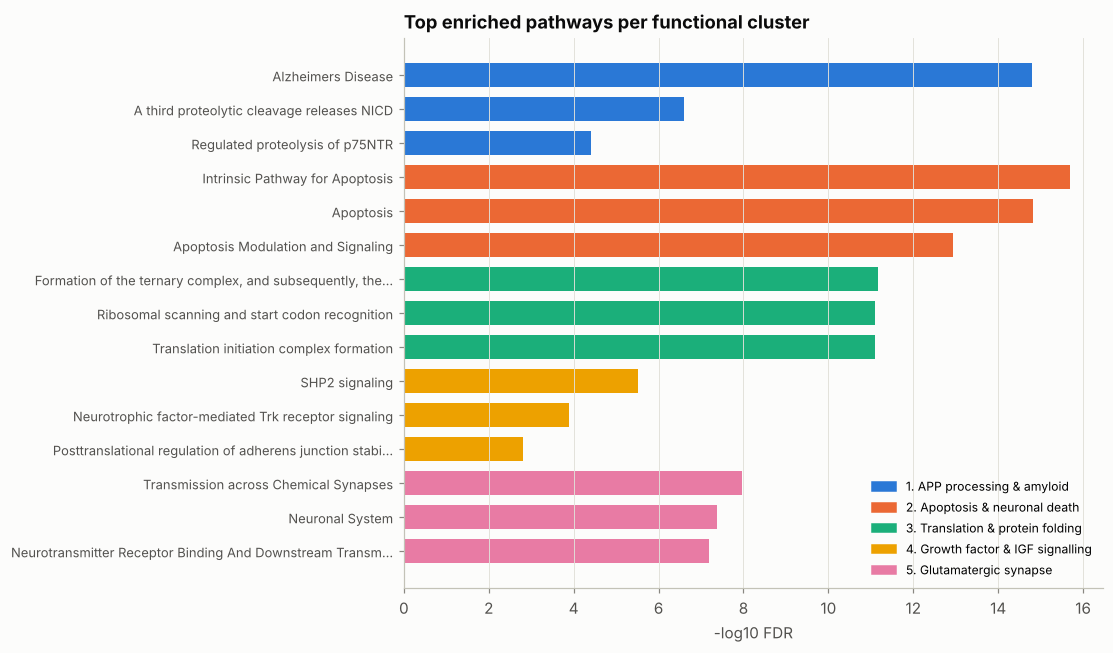

,cluster,source,term,overlap,set_size,fdr
291,2,go_bp,regulation of neuron death,26,248,5.121e-25
292,2,go_bp,intrinsic apoptotic signaling pathway,21,168,3.185e-21
90,2,pathway,Intrinsic Pathway for Apoptosis,12,38,2.080e-16
0,1,pathway,Alzheimers Disease,14,79,1.599e-15
91,2,pathway,Apoptosis,14,84,1.544e-15
1429,3,pathway,"Formation of the ternary complex, and subsequently, the 43S complex",9,47,6.766e-12
1431,3,pathway,Translation initiation complex formation,9,54,7.776e-12
43,1,go_bp,membrane protein ectodomain proteolysis,7,19,1.800e-08
1767,5,go_bp,single-organism behavior,8,373,4.823e-08
1752,5,pathway,Transmission across Chemical Synapses,7,188,1.070e-08


In [11]:
annotated = set().union(*data.pathways.values()) | set().union(*data.go_processes.values())
enrichment = enrich_clusters(labels, {"pathway": data.pathways, "go_bp": data.go_processes},
                             set(interactome) & annotated, symbols, fdr=0.05)
names = {int(k): v for k, v in config["cluster_names"].items()}
plots.plot_cluster_enrichment(enrichment, names)
plt.show()
top = enrichment.sort_values("p_value").groupby(["cluster", "source"]).head(2)
top.assign(term=top["term"].map(clean_term))[["cluster", "source", "term", "overlap", "set_size", "fdr"]]

The network splits into five clusters (modularity 0.47), each with a clear functional signature:

| cluster | proteins | signature |
|---|---|---|
| 1. **APP processing & amyloid** | 62 | WikiPathways *Alzheimer's disease* (14 genes, FDR 1.6e-15), γ-secretase/NOTCH cleavage: APP, PSEN1/2, NCSTN, APH1A, BACE1, APOE |
| 2. **Apoptosis & neuronal death** | 59 | intrinsic apoptosis, BCL-2 family, regulation of neuron death: AKT1, TP53, BCL2, CASP3, SNCA, MAPT, GSK3B |
| 3. **Translation & protein folding** | 34 | ribosome / translation initiation and chaperones: HSP90AA1, HSPD1, ribosomal proteins (26 of 34 from DIAMOnD) |
| 4. **Growth factor & IGF signalling** | 26 | SHP2, Trk and IGF signalling: ESR1, IGF1R, INS, IGF1/2 |
| 5. **Glutamatergic synapse** | 9 | chemical synaptic transmission: DLG4 (PSD-95), GRIN2B, GRIA1, GRIK1/2 |

These map onto the main hypotheses of AD pathogenesis: amyloid processing, neuronal death, proteostasis,
insulin/IGF signalling ("type 3 diabetes") and synaptic failure. Louvain is randomised and the partition is
only moderately stable (mean ARI 0.70 across reruns), so the boundaries between the larger clusters should be
read as tendencies. The core memberships (APP/secretases, BCL-2 family, ribosome) are consistent.

**Next:** notebook 03 builds the styled Cytoscape views of this network.